# 2012 — AlexNet: ReLU, Dropout, Augmentation, GPUs

**Paper:** Alex Krizhevsky, Ilya Sutskever & Geoffrey Hinton, *"ImageNet Classification with Deep Convolutional Neural Networks"* (NeurIPS 2012).

AlexNet won ImageNet 2012 with a top-5 error of 15.3%, versus 26.2% for the runner-up, and started the deep learning boom. The architecture was a bigger LeNet; the difference came from the **ingredients**:

| Ingredient | Why it matters |
|---|---|
| **ReLU** $\max(0,z)$ | no saturation, so training is several times faster than tanh/sigmoid |
| **Dropout** (Hinton et al. 2012) | randomly zero units during training, which reduces co-adaptation and overfitting |
| **Data augmentation** | random crops/flips make the dataset effectively larger |
| **GPUs** | 2× GTX 580 made a 60M-parameter net trainable |
| Max-pooling, local response norm | (LRN was soon dropped) |

ImageNet is far too big for a notebook, so we run a **mini-AlexNet** on digits and test each ingredient.

![Diagram: AlexNet, scaled down (Krizhevsky, Sutskever & Hinton, 2012)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/17_2012_alexnet.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=32)]

In [3]:
class MiniAlexNet(nn.Module):
    def __init__(self, act="relu", dropout=0.5):
        super().__init__()
        A = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}[act]
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 5, padding=2), A(), nn.MaxPool2d(2),        # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), A(), nn.MaxPool2d(2),       # 16 -> 8
            nn.Conv2d(64, 96, 3, padding=1), A(),
            nn.Conv2d(96, 64, 3, padding=1), A(), nn.MaxPool2d(2),       # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout), nn.Linear(64 * 16, 256), A(),
            nn.Dropout(dropout), nn.Linear(256, 256), A(),
            nn.Linear(256, 10))
        # Initialise each activation sensibly: He/Kaiming for ReLU, Xavier/Glorot for saturating ones.
        # (With PyTorch's default init the 6-layer ReLU net barely moves at this learning rate.)
        for mod in self.modules():
            if isinstance(mod, (nn.Conv2d, nn.Linear)):
                if act == "relu": nn.init.kaiming_normal_(mod.weight, nonlinearity="relu")
                else: nn.init.xavier_normal_(mod.weight, gain=nn.init.calculate_gain(act))
                nn.init.zeros_(mod.bias)
    def forward(self, x): return self.classifier(self.features(x).flatten(1))

def augment(x):
    """Random translations of up to ±3 px (AlexNet used random crops + horizontal flips)."""
    pad = F.pad(x, (3, 3, 3, 3))
    i, j = np.random.randint(0, 7, 2)
    return pad[:, :, i:i + 32, j:j + 32]

def run(act="relu", dropout=0.5, aug=True, epochs=20, n_train=None, lr=0.01):
    seed_everything(0)
    m = MiniAlexNet(act, dropout).to(device)
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)   # AlexNet's optimizer
    X, Y = (Xtr, ytr) if n_train is None else (Xtr[:n_train], ytr[:n_train])
    losses, accs = [], []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(X), device=device); tot = 0
        for i in range(0, len(X), 64):
            idx = perm[i:i + 64]; xb = X[idx]
            if aug: xb = augment(xb)
            loss = F.cross_entropy(m(xb), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        losses.append(tot / len(X))
        m.eval()
        with torch.no_grad(): accs.append((m(Xte).argmax(1) == yte).float().mean().item())
    return losses, accs

## 1) ReLU vs. saturating activations

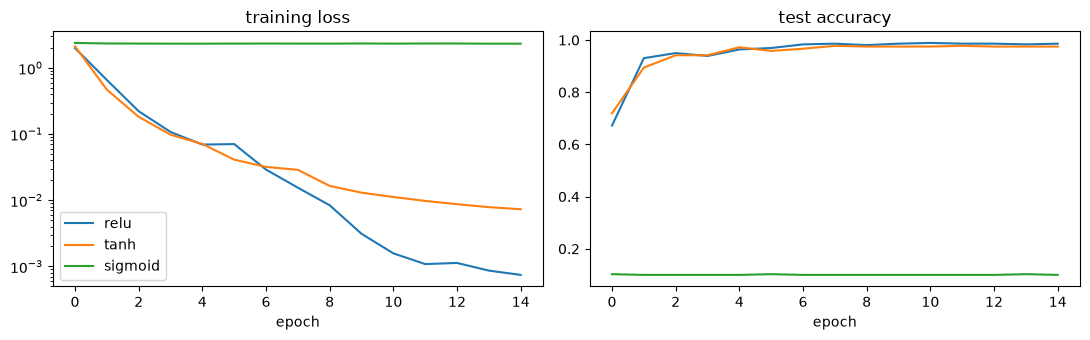

relu     final test acc 0.986
tanh     final test acc 0.975
sigmoid  final test acc 0.100


In [4]:
res = {a: run(act=a, dropout=0.0, aug=False, epochs=15) for a in ["relu", "tanh", "sigmoid"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (l, acc) in res.items():
    axes[0].plot(l, label=a); axes[1].plot(acc, label=a)
axes[0].set(title="training loss", xlabel="epoch", yscale="log"); axes[1].set(title="test accuracy", xlabel="epoch")
axes[0].legend(); plt.tight_layout(); plt.show()
for a, (l, acc) in res.items(): print(f"{a:8s} final test acc {acc[-1]:.3f}")

## 2) Dropout and augmentation against overfitting
With only **300 training images** the plain net memorises them; dropout and augmentation close the gap.

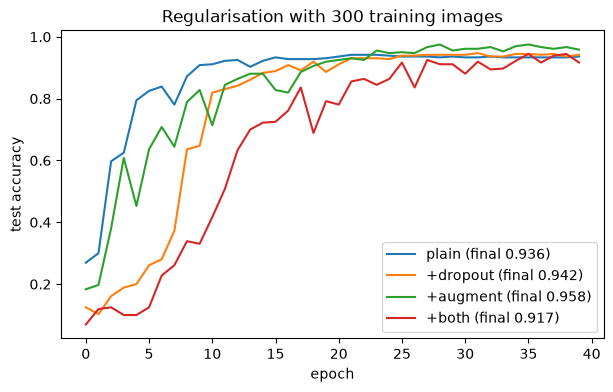

plain     final train loss 0.000  test acc 0.936
+dropout  final train loss 0.094  test acc 0.942
+augment  final train loss 0.022  test acc 0.958
+both     final train loss 0.328  test acc 0.917


In [5]:
configs = {"plain": dict(dropout=0.0, aug=False), "+dropout": dict(dropout=0.5, aug=False),
           "+augment": dict(dropout=0.0, aug=True), "+both": dict(dropout=0.5, aug=True)}
small = {k: run(n_train=300, epochs=40, **v) for k, v in configs.items()}
plt.figure(figsize=(7, 4))
for k, (l, acc) in small.items(): plt.plot(acc, label=f"{k} (final {acc[-1]:.3f})")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.title("Regularisation with 300 training images"); plt.legend(); plt.show()
for k, (l, acc) in small.items(): print(f"{k:9s} final train loss {l[-1]:.3f}  test acc {acc[-1]:.3f}")

## 3) GPU vs. CPU speed (only if you have a GPU)

In [6]:
def time_step(dev, n=20):
    m = MiniAlexNet().to(dev); x = torch.randn(256, 1, 32, 32, device=dev); y = torch.randint(0, 10, (256,), device=dev)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    for i in range(n + 3):
        if i == 3:
            if dev.type == "cuda": torch.cuda.synchronize()
            if dev.type == "mps": torch.mps.synchronize()
            t = time.time()
        loss = F.cross_entropy(m(x), y); opt.zero_grad(); loss.backward(); opt.step()
    if dev.type == "cuda": torch.cuda.synchronize()
    if dev.type == "mps": torch.mps.synchronize()
    return (time.time() - t) / n
cpu_t = time_step(torch.device("cpu"))
print(f"CPU: {cpu_t * 1000:.1f} ms / step")
if device.type != "cpu":
    gpu_t = time_step(device)
    print(f"{device.type.upper()}: {gpu_t * 1000:.1f} ms / step  ->  {cpu_t / gpu_t:.1f}x speed-up")
else:
    print("No GPU detected; that's fine, everything in this repo also runs on CPU.")

CPU: 311.8 ms / step


MPS: 27.9 ms / step  ->  11.2x speed-up
